In [7]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import optuna
import lightgbm as lgb
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
np.random.seed(SEED)
os.makedirs("../results", exist_ok=True)
os.makedirs("../figures", exist_ok=True)
print("Environment initialized with SEED =", SEED)

Environment initialized with SEED = 42


In [8]:
df = pd.read_csv("../data/Churn_Modelling.csv")

X = df.drop(columns=["RowNumber", "CustomerId", "Surname", "Exited"])
y = df["Exited"].values

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

cat_cols = ["Geography", "Gender"]
num_cols = [c for c in X.columns if c not in cat_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols),
        ("num", "passthrough", num_cols),
    ]
)

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print(f"Train shape: {X_train.shape} | Test shape: {X_test.shape}")

Train shape: (8000, 11) | Test shape: (2000, 11)


In [11]:
def measure_latency_ms(model, X_sample, n_repeats=15):
    for _ in range(3):
        _ = model.predict_proba(X_sample)
    latencies = []
    for _ in range(n_repeats):
        t0 = time.perf_counter()
        _ = model.predict_proba(X_sample)
        t1 = time.perf_counter()
        latencies.append((t1 - t0) * 1000.0)
    return np.median(latencies) * (1000.0 / len(X_sample))

def evaluate_config(params):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    aucs, latencies = [], []
    for train_idx, val_idx in skf.split(X_train, y_train):
        X_tr, y_tr = X_train[train_idx], y_train[train_idx]
        X_va, y_va = X_train[val_idx], y_train[val_idx]
        
        clf = lgb.LGBMClassifier(**params, random_state=SEED, n_jobs=-1, verbose=-1)
        clf.fit(X_tr, y_tr)
        
        preds = clf.predict_proba(X_va)[:, 1]
        aucs.append(roc_auc_score(y_va, preds))
        latencies.append(measure_latency_ms(clf, X_va, n_repeats=15))
    return float(np.mean(aucs)), float(np.mean(latencies))

# 1. Baseline 1: Default LightGBM
default_params = {
    "n_estimators": 100,
    "max_depth": -1,
    "learning_rate": 0.1,
    "num_leaves": 31,
    "min_child_samples": 20,
}
def_auc, def_lat = evaluate_config(default_params)
pd.DataFrame([{
    "method": "Default_LightGBM",
    "trial": 0,
    **default_params,
    "cv_roc_auc": def_auc,
    "cv_latency_ms_per_1k": def_lat
}]).to_csv("../results/baseline_default.csv", index=False)

print(f"[Baseline 1 - Default] CV ROC-AUC: {def_auc:.4f} | Latency: {def_lat:.4f} ms/1k")

# 2. Baseline 2: Random Search (40 trials - có thanh tiến trình)
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 500),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 127),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 100),
    }
    return evaluate_config(params)

study_random = optuna.create_study(
    directions=["maximize", "minimize"],
    sampler=optuna.samplers.RandomSampler(seed=SEED)
)
study_random.optimize(objective, n_trials=40, show_progress_bar=True)

df_random = study_random.trials_dataframe()
df_random["method"] = "Random_Search"
df_random.to_csv("../results/baseline_random_search.csv", index=False)
print("[Baseline 2 - Random Search] Completed 40 trials.")

[Baseline 1 - Default] CV ROC-AUC: 0.8606 | Latency: 3.7563 ms/1k


  0%|          | 0/40 [00:00<?, ?it/s]

[Baseline 2 - Random Search] Completed 40 trials.


In [12]:
# 3. Proposed Method: Optuna NSGA-II (40 trials)
study_nsga2 = optuna.create_study(
    directions=["maximize", "minimize"],
    sampler=optuna.samplers.NSGAIISampler(population_size=10, seed=SEED)
)
study_nsga2.optimize(objective, n_trials=40, show_progress_bar=True)

df_nsga2 = study_nsga2.trials_dataframe()
df_nsga2["method"] = "NSGA_II"
df_nsga2.to_csv("../results/nsga2_trials.csv", index=False)

# Trích xuất tập nghiệm không bị trội (Pareto-optimal front)
pareto_trials = study_nsga2.best_trials
pareto_records = []
for t in pareto_trials:
    pareto_records.append({
        "trial": t.number,
        **t.params,
        "cv_roc_auc": t.values[0],
        "cv_latency_ms_per_1k": t.values[1]
    })

df_pareto = pd.DataFrame(pareto_records).sort_values(by="cv_roc_auc", ascending=False)
df_pareto.to_csv("../results/nsga2_pareto_front.csv", index=False)

print(f"[Proposed - NSGA-II] Found {len(df_pareto)} Pareto-optimal solutions:")
display(df_pareto)

  0%|          | 0/40 [00:00<?, ?it/s]

[Proposed - NSGA-II] Found 5 Pareto-optimal solutions:


,trial,n_estimators,max_depth,learning_rate,num_leaves,min_child_samples,cv_roc_auc,cv_latency_ms_per_1k
3,25,414,4,0.027011,92,35,0.864644,11.734150
4,30,83,3,0.286914,82,42,0.864008,2.618512
0,1,120,3,0.190304,82,74,0.861996,2.580612
1,2,59,12,0.169675,38,26,0.854894,2.520112
2,21,70,4,0.030238,58,74,0.854541,2.186150


=== FINAL HOLD-OUT TEST SET EVALUATION (2,000 SAMPLES) ===


,Configuration,n_estimators,max_depth,learning_rate,num_leaves,min_child_samples,Holdout_Test_ROC_AUC,Holdout_Test_Latency_ms_per_1k
0,Default LightGBM,100,-1,0.1000,31,20,0.8633,2.3043
1,NSGA-II #25 (Max-AUC),414,4,0.0270,92,35,0.8703,11.3688
2,NSGA-II #30 (Knee-Point / Selected),83,3,0.2869,82,42,0.8641,2.4611
3,NSGA-II #21 (Min-Latency),70,4,0.0302,58,74,0.8593,2.6057


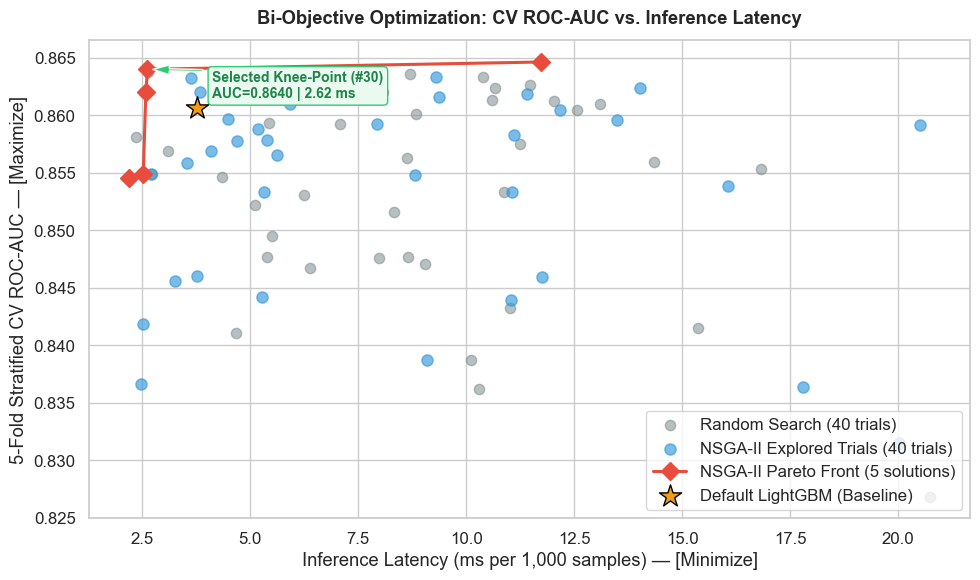

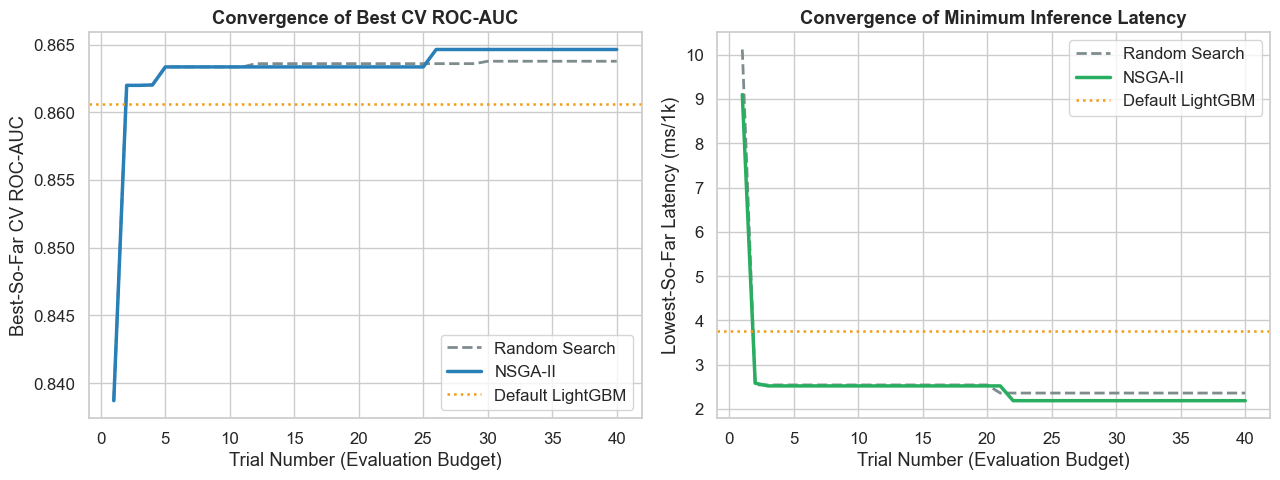

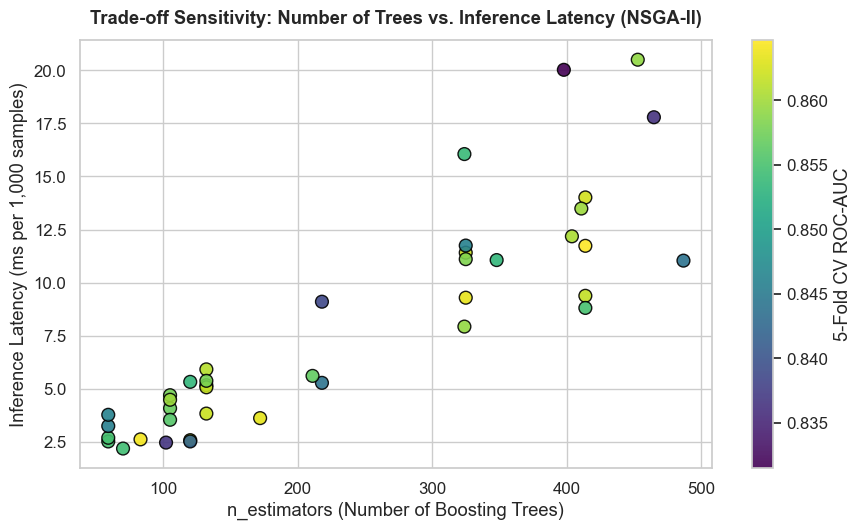

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.1)

# --- PHẦN A: ĐÁNH GIÁ TRÊN TẬP HOLD-OUT TEST (20% CHƯA TỪNG THẤY) ---
# Chọn 4 đại diện tiêu biểu: Default, NSGA-II Max-AUC (#25), NSGA-II Knee-Point (#30), NSGA-II Min-Latency (#21)
candidates = [
    ("Default LightGBM", default_params),
    ("NSGA-II #25 (Max-AUC)", study_nsga2.trials[25].params),
    ("NSGA-II #30 (Knee-Point / Selected)", study_nsga2.trials[30].params),
    ("NSGA-II #21 (Min-Latency)", study_nsga2.trials[21].params),
]

test_results = []
for name, p in candidates:
    clf = lgb.LGBMClassifier(**p, random_state=SEED, n_jobs=-1, verbose=-1)
    clf.fit(X_train, y_train)
    test_probs = clf.predict_proba(X_test)[:, 1]
    test_auc = roc_auc_score(y_test, test_probs)
    test_lat = measure_latency_ms(clf, X_test, n_repeats=30)
    test_results.append({
        "Configuration": name,
        "n_estimators": p["n_estimators"],
        "max_depth": p["max_depth"],
        "learning_rate": round(p["learning_rate"], 4),
        "num_leaves": p["num_leaves"],
        "min_child_samples": p["min_child_samples"],
        "Holdout_Test_ROC_AUC": round(test_auc, 4),
        "Holdout_Test_Latency_ms_per_1k": round(test_lat, 4)
    })

df_test_eval = pd.DataFrame(test_results)
df_test_eval.to_csv("../results/final_test_evaluation.csv", index=False)
print("=== FINAL HOLD-OUT TEST SET EVALUATION (2,000 SAMPLES) ===")
display(df_test_eval)

# --- PHẦN B: XUẤT 3 BIỂU ĐỒ CHẤT LƯỢNG CAO VÀO THƯ MỤC figures/ ---

# Biểu đồ 1: So sánh Không gian Mục tiêu & Đường biên Pareto (Random Search vs NSGA-II vs Default)
plt.figure(figsize=(10, 6))
plt.scatter(
    df_random["values_1"], df_random["values_0"],
    alpha=0.55, color="#7f8c8d", s=55, label="Random Search (40 trials)"
)
plt.scatter(
    df_nsga2["values_1"], df_nsga2["values_0"],
    alpha=0.65, color="#3498db", s=65, label="NSGA-II Explored Trials (40 trials)"
)

# Nối đường biên Pareto của NSGA-II
df_pareto_sorted = df_pareto.sort_values(by="cv_latency_ms_per_1k")
plt.plot(
    df_pareto_sorted["cv_latency_ms_per_1k"], df_pareto_sorted["cv_roc_auc"],
    color="#e74c3c", marker="D", markersize=9, linewidth=2.2, label="NSGA-II Pareto Front (5 solutions)"
)

# Đánh dấu Default LightGBM và Knee Point (#30)
plt.scatter(
    [def_lat], [def_auc],
    color="#f39c12", marker="*", s=280, edgecolor="black", zorder=5, label="Default LightGBM (Baseline)"
)
knee_row = df_pareto[df_pareto["trial"] == 30].iloc[0]
plt.annotate(
    "Selected Knee-Point (#30)\nAUC=0.8640 | 2.62 ms",
    xy=(knee_row["cv_latency_ms_per_1k"], knee_row["cv_roc_auc"]),
    xytext=(knee_row["cv_latency_ms_per_1k"] + 1.5, knee_row["cv_roc_auc"] - 0.0025),
    arrowprops=dict(facecolor="#2ecc71", shrink=0.08, width=1.5, headwidth=7),
    fontsize=10, fontweight="bold", color="#1e8449",
    bbox=dict(boxstyle="round,pad=0.3", fc="#eafaf1", ec="#2ecc71")
)

plt.title("Bi-Objective Optimization: CV ROC-AUC vs. Inference Latency", fontweight="bold", pad=12)
plt.xlabel("Inference Latency (ms per 1,000 samples) — [Minimize]")
plt.ylabel("5-Fold Stratified CV ROC-AUC — [Maximize]")
plt.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.savefig("../figures/01_pareto_front_comparison.png", dpi=300)
plt.show()

# Biểu đồ 2: Quá trình hội tụ theo số lần đánh giá (Convergence Trajectory)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Best-so-far CV ROC-AUC
axes[0].plot(df_random["number"] + 1, df_random["values_0"].cummax(), linestyle="--", color="#7f8c8d", linewidth=2, label="Random Search")
axes[0].plot(df_nsga2["number"] + 1, df_nsga2["values_0"].cummax(), color="#2980b9", linewidth=2.5, label="NSGA-II")
axes[0].axhline(def_auc, color="#f39c12", linestyle=":", linewidth=1.8, label="Default LightGBM")
axes[0].set_title("Convergence of Best CV ROC-AUC", fontweight="bold")
axes[0].set_xlabel("Trial Number (Evaluation Budget)")
axes[0].set_ylabel("Best-So-Far CV ROC-AUC")
axes[0].legend()

# Subplot 2: Best-so-far Minimum Latency
axes[1].plot(df_random["number"] + 1, df_random["values_1"].cummin(), linestyle="--", color="#7f8c8d", linewidth=2, label="Random Search")
axes[1].plot(df_nsga2["number"] + 1, df_nsga2["values_1"].cummin(), color="#27ae60", linewidth=2.5, label="NSGA-II")
axes[1].axhline(def_lat, color="#f39c12", linestyle=":", linewidth=1.8, label="Default LightGBM")
axes[1].set_title("Convergence of Minimum Inference Latency", fontweight="bold")
axes[1].set_xlabel("Trial Number (Evaluation Budget)")
axes[1].set_ylabel("Lowest-So-Far Latency (ms/1k)")
axes[1].legend()

plt.tight_layout()
plt.savefig("../figures/02_convergence_history.png", dpi=300)
plt.show()

# Biểu đồ 3: Tác động của siêu tham số (n_estimators & max_depth) lên độ trễ & độ chính xác
plt.figure(figsize=(9, 5.5))
sc = plt.scatter(
    df_nsga2["params_n_estimators"], df_nsga2["values_1"],
    c=df_nsga2["values_0"], cmap="viridis", s=85, edgecolor="black", alpha=0.9
)
cbar = plt.colorbar(sc)
cbar.set_label("5-Fold CV ROC-AUC")
plt.title("Trade-off Sensitivity: Number of Trees vs. Inference Latency (NSGA-II)", fontweight="bold", pad=12)
plt.xlabel("n_estimators (Number of Boosting Trees)")
plt.ylabel("Inference Latency (ms per 1,000 samples)")
plt.tight_layout()
plt.savefig("../figures/03_hyperparameter_tradeoff.png", dpi=300)
plt.show()